<a href="https://colab.research.google.com/github/LIONPANJSHIR/Row-Health/blob/main/Overviews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from os import set_inheritable
from pathlib import Path
from google.colab import drive
import pandas as pd
import numpy as np

# drive.mount('/content/drive')
project_dir = Path("/content/drive/MyDrive/project/data_analytics/row_heatheart")


# mettre peoject_dir comme repertoire principale
%cd {project_dir}

# importer les données nettoyer

# claims.to_csv(clean_dir / "claims.csv", index=False)
# customers.to_csv(clean_dir / "customers.csv", index=False)
# campagne.to_csv(clean_dir / "campaigns.csv", index=False)

claims = pd.read_csv(project_dir / "data/clean/claims.csv")
customers = pd.read_csv(project_dir / "data/clean/customers.csv")
campagne = pd.read_csv(project_dir / "data/clean/campaigns.csv")



/content/drive/MyDrive/project/data_analytics/row_heatheart


# PHASE 3: BUSINESS ANALYSIS

> ## Comment Row Health peut-elle optimiser son budget marketing pour augmenter les inscriptions à moindre coût, tout en préservant sa visibilité et en comprenant mieux les profils des clients acquis ?

In [2]:
# @title
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
campagne

,campaign_id,campaign_category,campaign_type,cost,platform,impressions,clicks,days_run,clicks_missing_flag,clicks_fractional_flag,clicks_gt_impressions_flag,ctr_applicable_flag,clicks_raw
0,CAM033,Health For All,Product Promotion,846.052987,TV,32272,0.0,27,False,False,False,False,0.0
1,CAM051,Health For All,Policy Information,1253.532835,TV,20437,0.0,11,False,False,False,False,0.0
2,CAM057,Health For All,Health Awareness,1062.209448,TV,29630,0.0,17,False,False,False,False,0.0
3,CAM032,Family Coverage Plan,Product Promotion,801.456917,TV,452680,NaN,27,True,False,False,False,NaN
4,CAM036,Golden Years Security,Covid Awareness,301.467866,TV,25492,0.0,13,False,False,False,False,0.0
5,CAM041,Golden Years Security,Covid Awareness,571.719463,TV,35448,0.0,11,False,False,False,False,0.0
6,CAM053,Golden Years Security,Product Promotion,338.275359,TV,13480,0.0,12,False,False,False,False,0.0
7,CAM010,Affordable Plans,Covid Awareness,820.580377,SEO,221170,12460.0,27,False,False,False,True,12460.0
8,CAM028,Affordable Plans,Policy Information,300.126002,SEO,84850,27785.0,27,False,False,False,True,27785.0
9,CAM045,Affordable Plans,Covid Awareness,448.441110,SEO,21487,1349.0,18,False,True,False,True,1348.5


### AXE A : Executive Overview

In [4]:
# @title
# claims_agg = (
#     claims.groupby("customer_id", as_index=False)
#     .agg(
#         nb_claims=("claim_id", "nunique"),
#         total_claimed=("claim_amount", "sum"),
#         total_covered=("covered_amount", "sum")
#     )
# )

table_1 = (
    customers#.loc[: , [ ]]
    .join(
        campagne.set_index("campaign_id"),
        on="campaign_id",
        how="left",
        validate="many_to_one"
    )
    # .join(
    #     claims_agg.set_index("customer_id"),
    #     on="customer_id",
    #     how="left",
    #     validate="one_to_one"
    # )
)



# 1. Nombre d'inscriptions attribuées à chaque campagne
signups = (
    table_1[
        table_1["campaign_id"].isin(campagne["campaign_id"])
    ]
    .groupby("campaign_id", as_index=False)
    .agg(inscriptions=("customer_id", "nunique"))
)

# 2. Réintégrer toutes les campagnes, même sans inscription attribuée
campaign_kpis = campagne.merge(
    signups,
    on="campaign_id",
    how="left",
    validate="one_to_one"
)

campaign_kpis["inscriptions"] = (
    campaign_kpis["inscriptions"].fillna(0).astype(int)
)

# 3. Calcul des KPI
campaign_kpis["CPS"] = (
    campaign_kpis["cost"]
    .div(campaign_kpis["inscriptions"].replace(0, np.nan))
)

campaign_kpis["Signup_Rate"] = (
    campaign_kpis["inscriptions"]
    .div(campaign_kpis["impressions"].replace(0, np.nan))
    * 100
)

campaign_kpis["CTR"] = np.where(
    (campaign_kpis["platform"] != "TV")
    & campaign_kpis["clicks"].notna()
    & (campaign_kpis["impressions"] > 0),
    campaign_kpis["clicks"] / campaign_kpis["impressions"] * 100,
    np.nan
)

campaign_kpis["Cost_per_Impression"] = (
    campaign_kpis["cost"]
    .div(campaign_kpis["impressions"].replace(0, np.nan))
)

campaign_kpis["Budget_Share"] = (
    campaign_kpis["cost"] / campaign_kpis["cost"].sum() * 100
)

campaign_kpis["Signup_Share"] = (
    campaign_kpis["inscriptions"]
    / campaign_kpis["inscriptions"].sum() * 100
)

cols = campaign_kpis.columns[ ~campaign_kpis.columns.str.contains('flag')]
campaign_kpis = campaign_kpis[cols].copy()

campaign_kpis.to_csv('/content/drive/MyDrive/project/data_analytics/row_heatheart/data/output/campaign_kpis.csv' , index=False)

print("heaad 5")
campaign_kpis.head(5)





heaad 5


,campaign_id,campaign_category,campaign_type,cost,platform,impressions,clicks,days_run,clicks_raw,inscriptions,CPS,Signup_Rate,CTR,Cost_per_Impression,Budget_Share,Signup_Share
0,CAM033,Health For All,Product Promotion,846.052987,TV,32272,0.0,27,0.0,266,3.180650,0.824244,NaN,0.026216,1.405631,1.633004
1,CAM051,Health For All,Policy Information,1253.532835,TV,20437,0.0,11,0.0,0,NaN,0.000000,NaN,0.061336,2.082618,0.000000
2,CAM057,Health For All,Health Awareness,1062.209448,TV,29630,0.0,17,0.0,0,NaN,0.000000,NaN,0.035849,1.764753,0.000000
3,CAM032,Family Coverage Plan,Product Promotion,801.456917,TV,452680,NaN,27,NaN,228,3.515162,0.050367,NaN,0.001770,1.331539,1.399718
4,CAM036,Golden Years Security,Covid Awareness,301.467866,TV,25492,0.0,13,0.0,0,NaN,0.000000,NaN,0.011826,0.500858,0.000000


In [5]:
# @title

total_signups = table_1["customer_id"].nunique()
attributed_signups = campaign_kpis["inscriptions"].sum()
total_budget = campaign_kpis["cost"].sum()

# Campagnes digitales dont les clics sont renseignés
digital_valid = campaign_kpis[
    (campaign_kpis["platform"] != "TV")
    & campaign_kpis["clicks"].notna()
    & (campaign_kpis["impressions"] > 0)
]

kpis_global = pd.Series({
    "Total campagnes": campaign_kpis["campaign_id"].nunique(),
    "Total inscriptions": total_signups,
    "Inscriptions attribuées": attributed_signups,
    "Taux attribution (%)": round(
        attributed_signups / total_signups * 100, 2
    ),
    "Budget marketing ($)": round(total_budget, 2),
    "Impressions": campaign_kpis["impressions"].sum(),
    "Clics enregistrés": campaign_kpis["clicks"].sum(),
    "CPS global $": round(total_budget / attributed_signups, 2),
    "CTR digital (%)": round(
        digital_valid["clicks"].sum()
        / digital_valid["impressions"].sum() * 100, 2
    )
})


kpis_global.to_csv('/content/drive/MyDrive/project/data_analytics/row_heatheart/data/output/kpis_global.csv' , index=False)

display(kpis_global.to_frame("Valeur"))



,Valeur
Total campagnes,57.00
Total inscriptions,16338.00
Inscriptions attribuées,16289.00
Taux attribution (%),99.70
Budget marketing ($),60190.25
Impressions,9080155.00
Clics enregistrés,852272.00
CPS global $,3.70
CTR digital (%),10.90


In [6]:
# @title


# platform_kpis = (
#     campaign_kpis
#     .groupby("platform", as_index=False)
#     .agg(
#         campagnes=("campaign_id", "nunique"),
#         budget=("cost", "sum"),
#         impressions=("impressions", "sum"),
#         inscriptions=("inscriptions", "sum")
#     )
# )

# platform_kpis["CPS"] = (
#     platform_kpis["budget"]
#     / platform_kpis["inscriptions"].replace(0, np.nan)
# )

# platform_kpis["Budget_Share"] = (
#     platform_kpis["budget"] / total_budget * 100
# )

# platform_kpis["Signup_Share"] = (
#     platform_kpis["inscriptions"] / attributed_signups * 100
# )

# platform_kpis["Signup_Rate"] = (
#     platform_kpis["inscriptions"]
#     / platform_kpis["impressions"] * 100
# )

# # CTR : uniquement les campagnes digitales avec clics renseignés
# ctr_platform = (
#     digital_valid
#     .groupby("platform")
#     .agg(
#         valid_clicks=("clicks", "sum"),
#         valid_impressions=("impressions", "sum")
#     )
# )

# ctr_platform["CTR"] = (
#     ctr_platform["valid_clicks"]
#     / ctr_platform["valid_impressions"] * 100
# )

# platform_kpis = platform_kpis.merge(
#     ctr_platform[["CTR"]],
#     left_on="platform",
#     right_index=True,
#     how="left"
# )

# platform_kpis['Allocation_Gap'] = platform_kpis['Signup_Share'] - platform_kpis['Budget_Share']



# platform_kpis.to_csv('/content/drive/MyDrive/project/data_analytics/row_heatheart/data/output/platforme_resume.csv' , index=False)


# platform_kpis


In [7]:
# Q2 — Répartition par type de campagne
campaign_type_distribution = (
    campaign_kpis
    .groupby("campaign_type")
    .agg(nb_campagnes=("campaign_id", "nunique"))
    .sort_values("nb_campagnes", ascending=False)
)

# Q9 — Campagnes sans inscription attribuée
nb_campagnes_sans_attribution = (
    campaign_kpis["inscriptions"] == 0
).sum()

taux_campagnes_sans_attribution = (
    nb_campagnes_sans_attribution
    / campaign_kpis["campaign_id"].nunique()
    * 100
)

print(campaign_type_distribution)
print('total:' )
print(
    f"\nCampagnes sans inscription attribuée : "
    f"{nb_campagnes_sans_attribution}"
)
print(
    f"Proportion : "
    f"{taux_campagnes_sans_attribution:.2f}%"
)


                      nb_campagnes
campaign_type                     
Covid Awareness                 12
Product Promotion               12
Policy Information              10
Offer Announcement               6
Customer Testimonial             6
Health Tips                      6
Health Awareness                 5
total:

Campagnes sans inscription attribuée : 24
Proportion : 42.11%


In [8]:
from IPython.utils.py3compat import platform
# @title

platform_kpis = (
    campaign_kpis
    .groupby("platform", as_index=False)
    .agg(
        campagnes=("campaign_id", "nunique"),
        budget=("cost", "sum"),
        impressions=("impressions", "sum"),
        inscriptions=("inscriptions", "sum") ,
        cliks = ("clicks" , "sum")
    ).replace(0, np.nan)
)

platform_kpis["CPS"] = (
    platform_kpis["budget"]
    / platform_kpis["inscriptions"].replace(0, np.nan)
)

platform_kpis["Budget_Share"] = (
    platform_kpis["budget"] / total_budget * 100
)

platform_kpis["Signup_Share"] = (
    platform_kpis["inscriptions"] / attributed_signups * 100
)

platform_kpis["Signup_Rate"] = (
    platform_kpis["inscriptions"]
    / platform_kpis["impressions"] * 100
)

platform_kpis["CTR"] = (
    platform_kpis["cliks"]
    / platform_kpis["impressions"] * 100
)

# CTR : uniquement les campagnes digitales avec clics renseignés
# ctr_platform = (
#     digital_valid
#     .groupby("platform")
#     .agg(
#         valid_clicks=("clicks", "sum"),
#         valid_impressions=("impressions", "sum")
#     )
# )

# ctr_platform["CTR"] = (
#     ctr_platform["valid_clicks"]
#     / ctr_platform["valid_impressions"] * 100
# )

# platform_kpis = platform_kpis.merge(
#     ctr_platform[["CTR"]],
#     left_on="platform",
#     right_index=True,
#     how="left"
# )

platform_kpis['Allocation_Gap'] = platform_kpis['Signup_Share'] - platform_kpis['Budget_Share']



platform_kpis.to_csv('/content/drive/MyDrive/project/data_analytics/row_heatheart/data/output/platforme_resume.csv' , index=False)


display(platform_kpis.sort_values('inscriptions' , ascending=False))


,platform,campagnes,budget,impressions,inscriptions,cliks,CPS,Budget_Share,Signup_Share,Signup_Rate,CTR,Allocation_Gap
2,Social Media,16,17089.572975,3259312,7610,280849.0,2.245673,28.392594,46.718644,0.233485,8.616819,18.326050
0,Email,15,16678.967588,2022478,4130,337930.0,4.038491,27.710415,25.354534,0.204205,16.708711,-2.355881
1,SEO,19,21246.992710,3188926,4055,233493.0,5.239702,35.299726,24.894100,0.127159,7.321995,-10.405626
3,TV,7,5174.714875,609439,494,NaN,10.475131,8.597265,3.032721,0.081058,NaN,-5.564543


#### Insight 1 — Social Media domine l'acquisition malgré un CTR inférieur à Email

Les réseaux sociaux constituent le principal canal d'acquisition attribuée de Row Health, avec **7 610 inscriptions, soit 46,7 % du total**, contre 4 130 inscriptions (25,4 %) pour Email.

Avec des budgets relativement similaires (17 090 \$ contre 16 679 \$ ), Social Media génère **84 % d'inscriptions supplémentaires**, tout en affichant un coût par inscription nettement inférieur : **2,25  \$ contre 4,04  \$ pour Email**.

À l'inverse, Email présente un meilleur taux de clics (16,71 % contre environ 9,19 % pour Social Media, sur les campagnes disposant de données de clics valides), ce qui montre qu'un engagement publicitaire plus élevé ne se traduit pas nécessairement par davantage d'inscriptions attribuées.

**Implication business :** Social Media apparaît comme le canal le plus efficace historiquement en matière de coût par inscription. Il constitue donc une piste prioritaire pour examiner des opportunités d'optimisation budgétaire, sous réserve de vérifier les limites d'attribution et la stabilité des performances.

In [9]:
# @title
# category_kpis.query('campaign_category.isin(["#HealthyLiving" , "Health For All" , "#CoverageMatters"])')['signup_share'].sum()

In [10]:
# @title
# # campaign_kpis.query('campaign_category.isin(["#HealthyLiving" , "Health For All" , "#CoverageMatters"])')

pd.crosstab(
    index=campaign_kpis.query('campaign_category.isin(["#HealthyLiving" , "Health For All" , "#CoverageMatters"])')['campaign_category'] ,
    columns=campaign_kpis['platform']
)

platform,Email,Social Media,TV
campaign_category,,,
#CoverageMatters,0,3,0
#HealthyLiving,0,6,0
Health For All,1,0,3


In [11]:
# @title


catg= campaign_kpis.groupby('campaign_category').agg(
    cliks = ('clicks' , 'sum') ,
    impressions = ('impressions' , 'sum')
)
catg['CTR'] = catg['cliks'] / catg['impressions'] * 100


category_kpis = (
    campaign_kpis
    .groupby("campaign_category", as_index=False)
    .agg(
        nb_campagnes=("campaign_id", "nunique"),
        inscriptions=("inscriptions", "sum"),
        budget=("cost", "sum"),
        impressions=("impressions", "sum")
    )
)

# Coût par inscription attribuée
category_kpis["CPS"] = (
    category_kpis["budget"]
    / category_kpis["inscriptions"].replace(0, np.nan)
)

# Contribution de chaque catégorie aux inscriptions
category_kpis["signup_share"] = (
    category_kpis["inscriptions"]
    / category_kpis["inscriptions"].sum()*100
)

# Répartition du budget
category_kpis["budget_share"] = (
    category_kpis["budget"]
    / category_kpis["budget"].sum()*100
)

# Écart entre contribution et investissement
category_kpis["allocation_gap"] = (
    category_kpis["signup_share"]
    - category_kpis["budget_share"]
)


category_kpis["Signup_Rate"] = (
    category_kpis["inscriptions"]
    / category_kpis["impressions"] * 100
)

category_kpis = category_kpis.sort_values(
    "inscriptions", ascending=False
)


category_kpis = category_kpis.merge(
    catg['CTR'] ,
    left_on='campaign_category',
    right_index=True,
    how='left'
)


### Attention certains campagnes utilise en suplement des autres platforme La TV  donc a interpreter avec precaution



display(category_kpis.sort_values('signup_share' , ascending=False))


,campaign_category,nb_campagnes,inscriptions,budget,impressions,CPS,signup_share,budget_share,allocation_gap,Signup_Rate,CTR
1,#HealthyLiving,6,3727,6676.631363,1372448,1.791422,22.880471,11.092547,11.787925,0.271559,9.622805
8,Health For All,4,3545,4346.966301,170559,1.226225,21.763153,7.222044,14.541109,2.078460,25.476814
0,#CoverageMatters,3,3536,2311.331446,712100,0.653657,21.707901,3.840043,17.867858,0.496559,10.425502
5,Compare Health Coverage,8,2820,10043.207969,664710,3.561421,17.312297,16.685773,0.626524,0.424245,14.043718
11,Tailored Health Plans,5,1107,5175.185470,1398859,4.674964,6.795997,8.598046,-1.802049,0.079136,6.617536
9,Preventive Care News,6,643,6256.810157,1116968,9.730653,3.947449,10.395056,-6.447607,0.057567,12.235265
2,#InsureYourHealth,6,316,6572.881885,970244,20.800259,1.939959,10.920177,-8.980218,0.032569,7.682707
6,Family Coverage Plan,3,301,3936.412866,1106540,13.077784,1.847873,6.539951,-4.692078,0.027202,0.000000
10,Summer Wellness Tips,6,163,7085.680129,573010,43.470430,1.000675,11.772140,-10.771464,0.028446,18.091831
3,Affordable Plans,3,63,1569.147489,327507,24.907103,0.386764,2.606980,-2.220216,0.019236,12.700187


#### Insight 2 — Trois catégories concentrent l'essentiel des inscriptions attribuées, avec des niveaux d'efficacité très différents

Les catégories **#HealthyLiving, Health For All et #CoverageMatters** dominent l'acquisition marketing de Row Health. Ensemble, elles génèrent **10 808 inscriptions, soit 66,35 % du total**, pour seulement **22,15 % du budget marketing**.

Parmi elles, **#CoverageMatters se distingue par son efficacité budgétaire**. Avec 3 536 inscriptions attribuées, elle obtient un volume proche de celui de #HealthyLiving (3 727 inscriptions), tout en mobilisant **65,4 % de budget en moins**.

Cette différence se traduit par un coût par inscription de **0,65  \$ contre 1,79  \$**, soit une réduction d'environ 63,5 %.

Bien que #CoverageMatters enregistre presque deux fois moins d'impressions, son CTR reste légèrement supérieur (10,43 % contre 9,62 %). Les deux catégories utilisent exclusivement Social Media, ce qui rend leur comparaison particulièrement intéressante.

**Implication business :** #CoverageMatters représente une piste prometteuse pour améliorer l'efficacité des investissements sur les réseaux sociaux. Une analyse approfondie de ses campagnes individuelles est toutefois nécessaire avant d'envisager une augmentation du budget.


In [12]:
# @title
campaign_kpis.loc[
    campaign_kpis["campaign_category"] == "#CoverageMatters",
    [
        "campaign_id",
        "platform",
        "campaign_type",
        "cost",
        "impressions",
        "clicks",
        "inscriptions",
        "CPS",
        "CTR"
    ]
].sort_values("inscriptions", ascending=False)

,campaign_id,platform,campaign_type,cost,impressions,clicks,inscriptions,CPS,CTR
49,CAM031,Social Media,Product Promotion,806.421044,374710,29645.0,3534,0.228189,7.911452
47,CAM012,Social Media,Product Promotion,244.008996,72280,6010.0,1,244.008996,8.314887
48,CAM026,Social Media,Covid Awareness,1260.901406,265110,38585.0,1,1260.901406,14.554336


,count
signup_channel,
paid search,2176
Direct,637
Organic Search,464
Referral,121
Partner Referral,66
Social,31
provider partner,8
ZocDoc Ad,7
paid social,7


,proportion
plan,
silver,73.54
gold,25.04
bronze,1.30
platinum,0.11


signup_channel,Direct,External Display,InsuranceOfferAds,Organic Search,Other,Partner Referral,Referral,Social,ZocDoc Ad,email marketing,paid search,paid social,provider partner,All
first_touch,,,,,,,,,,,,,,
direct,3,0,0,3,0,2,1,0,0,0,28,0,1,38
email,0,0,0,1,0,0,0,0,0,0,4,0,0,5
marketplace,2,0,0,2,0,0,0,0,0,0,9,0,0,13
referral,144,2,1,122,1,10,26,5,1,2,653,3,1,971
social,488,3,1,336,5,54,94,26,6,2,1482,4,6,2507
All,637,5,2,464,6,66,121,31,7,4,2176,7,8,3534


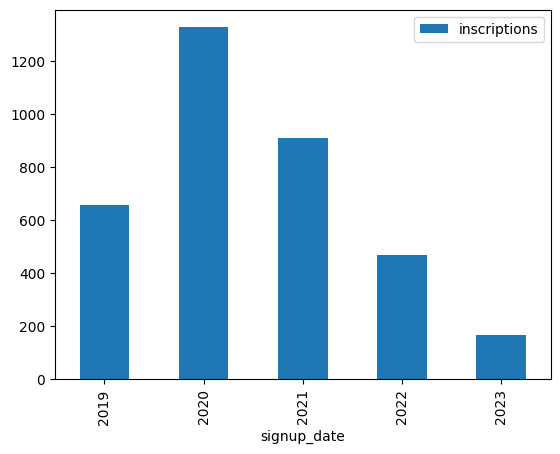

first_touch,direct,email,marketplace,referral,social
campaign_id,,,,,
CAM007,0.00,0.00,0.00,0.00,100.00
CAM026,0.00,0.00,0.00,0.00,100.00
CAM019,2.17,0.00,0.00,23.91,73.91
CAM031,1.08,0.14,0.37,27.48,70.94
CAM013,0.00,0.00,0.00,29.17,70.83
CAM023,0.00,0.00,0.00,36.36,63.64
CAM030,4.92,0.22,3.21,30.08,61.57
CAM020,2.68,0.00,1.65,36.46,59.22
CAM025,3.23,0.00,0.00,45.16,51.61


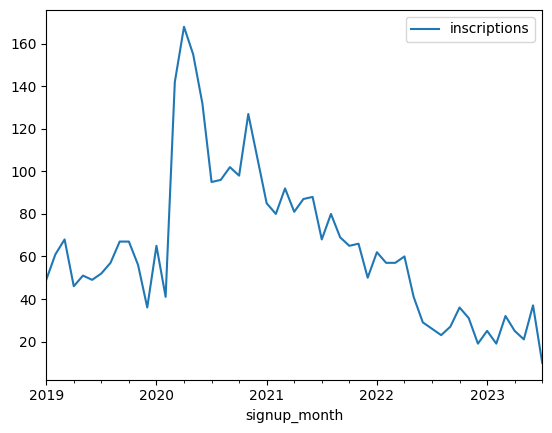

In [13]:
# @title
cam031_clients = customers.loc[
    customers["campaign_id"] == "CAM031"
]

# Répartition par canal d'inscription
display(
    cam031_clients["signup_channel"]
    .value_counts(dropna=False)
)

# Répartition par formule d'assurance
display(
    cam031_clients["plan"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

cam031 = customers.loc[
    customers["campaign_id"] == "CAM031"
].copy()

display(
    pd.crosstab(
        cam031["first_touch"],
        cam031["signup_channel"],
        margins=True
    )
)

cam031["signup_date"] = pd.to_datetime(
    cam031["signup_date"]
)

inscriptions_annuelles = (
    cam031
    .groupby(cam031["signup_date"].dt.year)
    .agg(inscriptions=("customer_id", "nunique"))
)

inscriptions_annuelles.plot(kind="bar")
plt.show()

social_campaigns = table_1.loc[
    table_1["platform"] == "Social Media"
]

first_touch_comparison = pd.crosstab(
    social_campaigns["campaign_id"],
    social_campaigns["first_touch"],
    normalize="index"
).mul(100).round(2)

display(
    first_touch_comparison.sort_values(
        "social", ascending=False
    )
)
# Évolution mensuelle des inscriptions
table =(
    cam031_clients
    .assign(
        signup_month=lambda df:
            pd.to_datetime(df["signup_date"])
            .dt.to_period("M")
    )
    .groupby("signup_month")
    .agg(inscriptions=("customer_id", "nunique"))
)

table.plot()
plt.show()

#### Insight 3 — La performance de #CoverageMatters repose presque exclusivement sur CAM031

La catégorie **#CoverageMatters** concentre 3 536 inscriptions attribuées, dont **99,94 % proviennent d'une seule campagne : CAM031**, qui représente seulement 34,9 % du budget de la catégorie.

Avec un **coût par inscription de 0,23  \$**, CAM031 surpasse largement CAM012 (244,01  \$) et CAM026 (1 260,90  \$).

Paradoxalement, CAM026 enregistre un CTR supérieur (14,55 % contre 7,91 % pour CAM031), mais une seule inscription attribuée.

**Interprétation business :** les performances de #CoverageMatters sont fortement concentrées et ne reflètent pas une efficacité homogène de ses campagnes. Un CTR élevé ne garantit pas un nombre élevé d'inscriptions attribuées.

**Implication stratégique :** CAM031 représente une piste d'optimisation à approfondir. Toutefois, la fiabilité de son attribution devra être vérifiée avant toute décision d'augmentation budgétaire.

In [14]:
# @title
## @title {"display-mode":"form"}


# catg= campaign_kpis.groupby('campaign_type').agg(
#     cliks = ('clicks' , 'sum') ,
#     impressions = ('impressions' , 'sum')
# )
# catg['CTR'] = catg['cliks'] / catg['impressions'] * 100


type_kpis = (
    campaign_kpis
    .groupby("campaign_type", as_index=False)
    .agg(
        nb_campagnes=("campaign_id", "nunique"),
        inscriptions=("inscriptions", "sum"),
        budget=("cost", "sum"),
        impressions=("impressions", "sum")
    )
)

# Coût par inscription attribuée
type_kpis["CPS"] = (
    type_kpis["budget"]
    / type_kpis["inscriptions"].replace(0, np.nan)
)

# Contribution de chaque catégorie aux inscriptions
type_kpis["signup_share"] = (
    type_kpis["inscriptions"]
    / type_kpis["inscriptions"].sum()*100
)

# Répartition du budget
type_kpis["budget_share"] = (
    type_kpis["budget"]
    / type_kpis["budget"].sum()*100
)

# Écart entre contribution et investissement
type_kpis["allocation_gap"] = (
    type_kpis["signup_share"]
    - type_kpis["budget_share"]
)


type_kpis["Signup_Rate"] = (
    type_kpis["inscriptions"]
    / type_kpis["impressions"] * 100
)

type_kpis = type_kpis.sort_values(
    "inscriptions", ascending=False
)


# type_kpis = type_kpis.merge(
#     catg['CTR'] ,
#     left_on='campaign_category',
#     right_index=True,
#     how='left'
# )

### Attention certains campagnes utilise en suplement des autres platforme La TV  donc a interpreter avec precaution
display(type_kpis.sort_values('signup_share' , ascending=False))

,campaign_type,nb_campagnes,inscriptions,budget,impressions,CPS,signup_share,budget_share,allocation_gap,Signup_Rate
6,Product Promotion,12,5581,10965.805894,1562824,1.964846,34.262386,18.218576,16.043810,0.357110
2,Health Awareness,5,3395,4520.521931,820960,1.331523,20.842286,7.510389,13.331897,0.413540
5,Policy Information,10,2987,10814.963725,1816321,3.620678,18.337528,17.967967,0.369562,0.164453
1,Customer Testimonial,6,2229,8676.854990,1511676,3.892712,13.684081,14.415716,-0.731634,0.147452
0,Covid Awareness,12,1064,13976.025031,1514805,13.135362,6.532015,23.219750,-16.687734,0.070240
3,Health Tips,6,972,5154.659153,719101,5.303147,5.967217,8.563944,-2.596727,0.135169
4,Offer Announcement,6,61,6081.417424,1134468,99.695368,0.374486,10.103659,-9.729173,0.005377


In [15]:
# @title
campaign_kpis.loc[
    campaign_kpis["campaign_type"] == "Health Awareness",
    [
        "campaign_id",
        "platform",
        "campaign_type",
        "cost",
        "impressions",
        "clicks",
        "inscriptions",
        "CPS",
        "CTR"
    ]
].sort_values("inscriptions", ascending=False)

,campaign_id,platform,campaign_type,cost,impressions,clicks,inscriptions,CPS,CTR
26,CAM018,Email,Health Awareness,1185.171031,88220,43453.0,3279,0.361443,49.255271
14,CAM009,SEO,Health Awareness,394.641083,480790,34210.0,114,3.461764,7.115373
36,CAM015,Email,Health Awareness,1555.577561,215420,41970.0,2,777.788781,19.482871
2,CAM057,TV,Health Awareness,1062.209448,29630,0.0,0,NaN,NaN
40,CAM055,Email,Health Awareness,322.922808,6900,4536.0,0,NaN,65.739130


#### Insight 4 — Trois types de campagnes concentrent 73,4 % des inscriptions, avec une efficacité budgétaire contrastée

Les campagnes **Product Promotion, Health Awareness et Policy Information** dominent l'acquisition attribuée de Row Health. Ensemble, elles génèrent **73,44 % des inscriptions pour seulement 43,7 % du budget marketing**, tout en représentant 47,4 % des campagnes.

Parmi elles, **Health Awareness se distingue par son efficacité budgétaire**. Avec seulement 7,51 % du budget total, ce type de campagne se positionne au deuxième rang des inscriptions attribuées (3 395), derrière Product Promotion (5 581).

Malgré un investissement inférieur de **58,8 %**, Health Awareness présente un **coût par inscription plus faible (1,33 \$ contre 1,96 \$)** et un taux d'inscription attribuée par impression légèrement supérieur (0,414 % contre 0,357 %).

Toutefois, l'analyse révèle une forte concentration des résultats : **CAM018 génère à elle seule 96,58 % des inscriptions de Health Awareness**, tout en mobilisant seulement 26,22 % de son budget.


**Interprétation business :** Product Promotion domine en volume d'inscriptions, tandis que Health Awareness affiche une meilleure efficacité budgétaire historique. Un investissement plus important ne se traduit donc pas nécessairement par un coût d'acquisition attribuée plus avantageux , de plus l'efficacité budgétaire observée pour Health Awareness est essentiellement portée par CAM018. Elle ne reflète donc pas une performance homogène de ce type de campagne



**Implication stratégique :** CAM018 constitue une piste d'investigation prioritaire, mais sa performance exceptionnelle et la fiabilité de son attribution doivent être examinées avant d'envisager une augmentation du budget.




In [16]:
# @title
top5 = campaign_kpis.nlargest(5, "inscriptions")

part_top5 = (
    top5["inscriptions"].sum()
    / campaign_kpis["inscriptions"].sum()
    * 100
)

print(f"Part des inscriptions du Top 5 : {part_top5:.2f}%")

display(
    top5[[
        "campaign_id",
        "platform",
        "campaign_category",
        "inscriptions",
        "cost",
        "CPS"
    ]]
)

part_budget_top5 = (
    top5["cost"].sum()
    / campaign_kpis["cost"].sum()
    * 100
)

print(f"Part du budget du Top 5 : {part_budget_top5:.2f}%")

Part des inscriptions du Top 5 : 75.97%


,campaign_id,platform,campaign_category,inscriptions,cost,CPS
49,CAM031,Social Media,#CoverageMatters,3534,806.421044,0.228189
26,CAM018,Email,Health For All,3279,1185.171031,0.361443
44,CAM030,Social Media,#HealthyLiving,2743,1362.207577,0.496612
18,CAM004,SEO,Compare Health Coverage,1546,1354.937186,0.876415
19,CAM006,SEO,Compare Health Coverage,1273,1254.286130,0.985299


Part du budget du Top 5 : 9.91%


#### Insight 5 — Cinq campagnes concentrent près de 76 % des inscriptions pour moins de 10 % du budget

L'analyse des 57 campagnes marketing révèle une **forte concentration des performances d'acquisition** : les cinq campagnes les plus performantes génèrent **12 375 inscriptions, soit 75,97 % du total attribué**, tout en mobilisant seulement **9,91 % du budget marketing**.

Ces campagnes présentent un coût par inscription agrégé particulièrement faible de **0,48 \$**, contre **13,85 \$ pour les 52 autres campagnes**.

Fait notable, ces cinq campagnes sont réparties entre trois plateformes : Social Media, Email et SEO.

**Interprétation business :** les performances d'acquisition attribuée de Row Health reposent principalement sur un nombre restreint de campagnes. Les résultats agrégés par plateforme peuvent donc masquer des disparités importantes entre campagnes individuelles.

**Implication stratégique :** l'optimisation budgétaire devrait s'appuyer sur une analyse des campagnes individuelles plutôt que sur les seules moyennes par canal. Avant toute réallocation, il sera nécessaire de vérifier la fiabilité de l'attribution, les objectifs des campagnes et la reproductibilité des performances observées.

#### Executive Summary — Key Findings

L'analyse des 57 campagnes marketing de Row Health révèle **16 289 inscriptions attribuées pour un budget total de 60 190 \$**, soit un coût moyen par inscription de 3,70 \$.

**1. Social Media domine l'acquisition attribuée.** Ce canal génère 46,7 % des inscriptions pour 28,4 % du budget marketing, avec un CPS de 2,25 \$, contre 4,04 \$ pour Email.

**2. Les résultats sont concentrés sur quelques catégories.** #HealthyLiving, Health For All et #CoverageMatters représentent 66,35 % des inscriptions attribuées pour seulement 22,15 % des dépenses.

**3. Cette performance agrégée masque une forte concentration individuelle.** CAM031 génère 99,94 % des inscriptions de #CoverageMatters. De même, CAM018 représente 96,58 % des inscriptions du type Health Awareness.

**4. Les performances d'acquisition ne sont pas nécessairement liées au niveau d'engagement.** Certaines campagnes affichent un CTR élevé malgré un faible nombre d'inscriptions attribuées.

**Conclusion business :** Row Health présente des écarts importants d'efficacité entre ses stratégies marketing. Les réseaux sociaux et certaines campagnes individuelles constituent des pistes d'optimisation, mais les limites d'attribution doivent être examinées avant de recommander des réallocations budgétaires.

In [17]:
category_kpis.to_csv(project_dir/'data/output/category_kpis', index=False)
type_kpis.to_csv(project_dir/'data/output/type_kpis', index=False)
platform_kpis.to_csv(project_dir/'data/output/platform_kpis', index=False)
campaign_kpis.to_csv(project_dir/'data/output/campaign_kpis' , index= False)

table_1.to_csv(project_dir/'data/output/table_1' , index= False)